<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_nonoise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 65.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit,transpile
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram

In [5]:
g = 0.5
delta_t = 1
omega = 2*g
N = 30
simualtor_aer = AerSimulator()

## Measuring Z

In [6]:
sz_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00',0) - ((results.get('01',0)))) / 1024
    sz_2.append(-valor)


### Drawing of the circuit

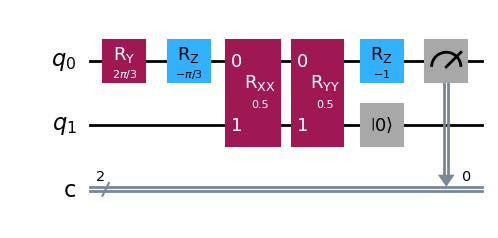

In [7]:

qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.measure(0,0)
qc.draw('mpl')

## Measuring X

In [8]:
sx_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.h(0)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00', 0) - (results.get('0q', 0))) / 1024
    sx_2.append(valor)

### Drawing of the Circuit

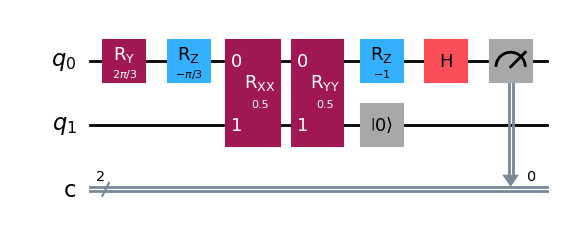

In [9]:
qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.h(0)
qc.measure(0,0)
qc.draw('mpl')

## Measuring Y

In [10]:
sy_2 = []
for niter in range(0,N):
    qc = QuantumCircuit(2,2)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    for i in range(0,niter):
        qc.rxx(g*delta_t,0,1)
        qc.ryy(g*delta_t,0,1)
        qc.rz(-omega*delta_t,0)
        qc.reset(1)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)
    job = simualtor_aer.run(qc,shots = 1024)
    results = job.result().get_counts()
    valor = (results.get('00', 0) - (results.get('01', 0))) / 1024
    sy_2.append(-valor)

### Drawing of the circuit

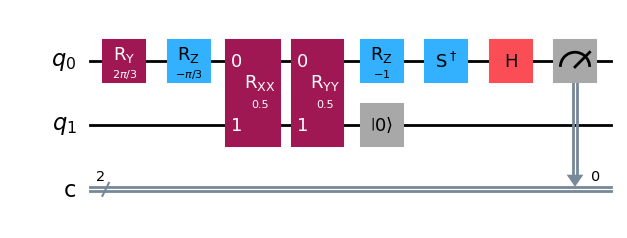

In [11]:
qc = QuantumCircuit(2,2)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
qc.rxx(g*delta_t,0,1)
qc.ryy(g*delta_t,0,1)
qc.rz(-omega*delta_t,0)
qc.reset(1)
qc.sdg(0)
qc.h(0)
qc.measure(0,0)
qc.draw('mpl')

## Plotting Expected Values

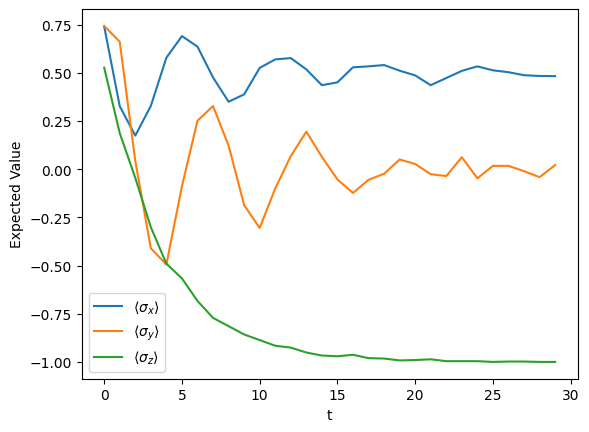

In [12]:
time = np.arange(N) * delta_t
plt.plot(time, sx_2,label=rf'$\langle \sigma_x\rangle$')
plt.plot(time, sy_2,label=rf'$\langle \sigma_y\rangle$')
plt.plot(time, sz_2,label=rf'$\langle \sigma_z\rangle$')

plt.xlabel('t')
plt.ylabel('Expected Value')
plt.legend()
datos = np.column_stack((time, sx_2, sy_2, sz_2))
